In [ ]:
import pandas as pd
from sklearn.preprocessing import OneHotEncoder

data = pd.read_csv("../../Data/df.csv")
data.head()
encoder = OneHotEncoder(handle_unknown="ignore")
encoded_city = encoder.fit_transform(data[["city"]])
print(encoded_city)
print(encoded_city.toarray())

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 6 stored elements and shape (6, 2)>
  Coords	Values
  (0, 0)	1.0
  (1, 1)	1.0
  (2, 0)	1.0
  (3, 1)	1.0
  (4, 0)	1.0
  (5, 1)	1.0
[[1. 0.]
 [0. 1.]
 [1. 0.]
 [0. 1.]
 [1. 0.]
 [0. 1.]]


In [10]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score)
from sklearn.inspection import permutation_importance
import pandas as pd
from sklearn.ensemble import GradientBoostingClassifier

data = pd.read_csv("../../Data/student_pass_fail.csv")

train_data, val_data, test_data = split_dataset(data)

features = ["hours_studied","attendance_pct","prev_score","sleep_hours"]

X_train = train_data[features]
y_train = train_data["passed"]
X_val = val_data[features]
y_val = val_data["passed"]
X_test = test_data[features]
y_test = test_data["passed"]

model = GradientBoostingClassifier(learning_rate = 0.1, n_estimators = 50, random_state = 1)
model.fit(X_train, y_train)
predictions = model.predict(X_val)

accuracy = accuracy_score(y_val, predictions)
precision = precision_score(y_val, predictions)
recall = recall_score(y_val, predictions)
f1 = f1_score(y_val, predictions)
print(f"Accuracy score is : {accuracy:.2%}")
print(f"Precision score is : {precision:.2%}")
print(f"Recall score is : {recall:.2%}")
print(f"F1 score is : {f1:.2%}")

train_pred = model.predict(X_train)
train_accuracy = accuracy_score(y_train, train_pred)
val_accuracy = accuracy_score(y_val, predictions)

print(f"Train accuracy is : {train_accuracy:.2%}")
print(f"Validation accuracy is : {val_accuracy:.2%}")

y_test_pred = model.predict(X_test)

test_accuracy = accuracy_score(y_test, y_test_pred)
test_precision = precision_score(y_test, y_test_pred)
test_recall = recall_score(y_test, y_test_pred)
test_f1 = f1_score(y_test, y_test_pred)

print(f"Test Accuracy score is : {test_accuracy:.2%}")
print(f"Test Precision score is : {test_precision:.2%}")
print(f"Test Recall score is : {test_recall:.2%}")
print(f"Test F1 score is : {test_f1:.2%}")


Accuracy score is : 74.00%
Precision score is : 73.50%
Recall score is : 80.37%
F1 score is : 76.79%
Train accuracy is : 75.62%
Validation accuracy is : 74.00%
Test Accuracy score is : 66.50%
Test Precision score is : 68.94%
Test Recall score is : 77.78%
Test F1 score is : 73.09%


In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score)
from sklearn.inspection import permutation_importance
import pandas as pd

data = pd.read_csv("../../Data/student_pass_fail.csv")

train_data, val_data, test_data = split_dataset(data)
features = ["hours_studied","attendance_pct","prev_score","sleep_hours"]
target = ["passed"]

X_train = train_data[features]
y_train = train_data["passed"]
X_val = val_data[features]
y_val = val_data["passed"]

model = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=10,
    random_state=1,
    oob_score=True
)
model.fit(X_train,y_train)

predictions = model.predict(X_val)


train_predictions = model.predict(X_train)
accuracy_train = accuracy_score(y_train, train_predictions)

val_accuracy = accuracy_score(y_val, predictions)

print(f"Train accuracy is : {accuracy_train:.2%}")
print(f"Validation accuracy is : {val_accuracy:.2%}")

X_test = test_data[features]
y_test = test_data["passed"]

y_test_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_test_pred)
precision = precision_score(y_test, y_test_pred)
recall = recall_score(y_test, y_test_pred)
f1 = f1_score(y_test, y_test_pred)
print(f"Accuracy score is : {accuracy:.2%}")
print(f"Precision score is : {precision:.2%}")
print(f"Recall score is : {recall:.2%}")
print(f"F1 score is : {f1:.2%}")



Train accuracy is : 80.88%
Validation accuracy is : 72.00%
Accuracy score is : 66.50%
Precision score is : 69.23%
Recall score is : 76.92%
F1 score is : 72.87%


In [69]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score)
import pandas as pd

data = pd.read_csv("../../Data/student_pass_fail.csv")

train_data, val_data, test_data = split_dataset(data)
features = ["hours_studied","attendance_pct","prev_score","sleep_hours"]
target = ["passed"]

X_train = train_data[features]
y_train = train_data["passed"]
X_val = val_data[features]
y_val = val_data["passed"]

model = DecisionTreeClassifier(max_depth = 6)
model.fit(X_train,y_train)
predictions = model.predict(X_val)

accuracy = accuracy_score(y_val, predictions)
precision = precision_score(y_val, predictions)
recall = recall_score(y_val, predictions)
f1 = f1_score(y_val, predictions)
print(f"Accuracy score is : {accuracy:.2%}")
print(f"Precision score is : {precision:.2%}")
print(f"Recall score is : {recall:.2%}")
print(f"F1 score is : {f1:.2%}")

# train_predictions = model.predict(X_train)
# accuracy_train = accuracy_score(y_train, train_predictions)
# print(f"Train accuracy is : {accuracy_train:.2%}")
# print(f"Validation accuracy is : {accuracy:.2%}")

Accuracy score is : 71.00%
Precision score is : 70.94%
Recall score is : 77.57%
F1 score is : 74.11%


[Text(0.4, 0.8333333333333334, 'x[1] <= 0.5\nsquared_error = 0.667\nsamples = 3\nvalue = 1.5'),
 Text(0.2, 0.5, 'squared_error = 0.0\nsamples = 1\nvalue = 0.5'),
 Text(0.30000000000000004, 0.6666666666666667, 'True  '),
 Text(0.6, 0.5, 'x[1] <= 1.5\nsquared_error = 0.25\nsamples = 2\nvalue = 2.0'),
 Text(0.5, 0.6666666666666667, '  False'),
 Text(0.4, 0.16666666666666666, 'squared_error = 0.0\nsamples = 1\nvalue = 1.5'),
 Text(0.8, 0.16666666666666666, 'squared_error = 0.0\nsamples = 1\nvalue = 2.5')]

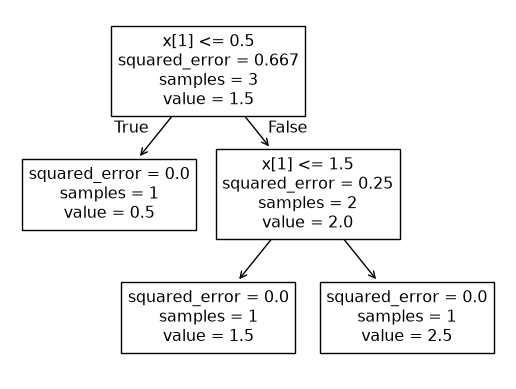

In [21]:
from sklearn import tree

X = [[0,0],[1,1],[2,2]]
Y = [0.5, 1.5, 2.5]
clf = tree.DecisionTreeRegressor()
clf.fit(X,Y)
tree.plot_tree(clf)

[Text(0.5, 0.9166666666666666, 'x[3] <= 0.8\ngini = 0.667\nsamples = 150\nvalue = [50, 50, 50]'),
 Text(0.4230769230769231, 0.75, 'gini = 0.0\nsamples = 50\nvalue = [50, 0, 0]'),
 Text(0.46153846153846156, 0.8333333333333333, 'True  '),
 Text(0.5769230769230769, 0.75, 'x[3] <= 1.75\ngini = 0.5\nsamples = 100\nvalue = [0, 50, 50]'),
 Text(0.5384615384615384, 0.8333333333333333, '  False'),
 Text(0.3076923076923077, 0.5833333333333334, 'x[2] <= 4.95\ngini = 0.168\nsamples = 54\nvalue = [0, 49, 5]'),
 Text(0.15384615384615385, 0.4166666666666667, 'x[3] <= 1.65\ngini = 0.041\nsamples = 48\nvalue = [0, 47, 1]'),
 Text(0.07692307692307693, 0.25, 'gini = 0.0\nsamples = 47\nvalue = [0, 47, 0]'),
 Text(0.23076923076923078, 0.25, 'gini = 0.0\nsamples = 1\nvalue = [0, 0, 1]'),
 Text(0.46153846153846156, 0.4166666666666667, 'x[3] <= 1.55\ngini = 0.444\nsamples = 6\nvalue = [0, 2, 4]'),
 Text(0.38461538461538464, 0.25, 'gini = 0.0\nsamples = 3\nvalue = [0, 0, 3]'),
 Text(0.5384615384615384, 0.25, '

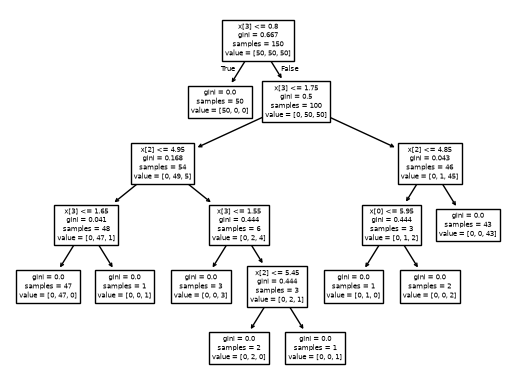

In [17]:
from sklearn.datasets import load_iris
from sklearn import tree
iris = load_iris()
X, y = iris.data, iris.target
clf = tree.DecisionTreeClassifier()
clf.fit(X, y)
tree.plot_tree(clf)

In [1]:
%run "../../Projects/Phase 4/splitting and baseline/splitter.py"

Train: 2400, Val: 300, Test: 300


In [2]:
%run "../../Projects/Phase 4/splitting and baseline/baseline.py"

In [ ]:
'''
1 import all required modules
2 import the dataset 
3 creat class bool
4 srateplit train val and test
5 choose features
'''
import pandas as pd
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score)
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

data = pd.read_csv("../../Data/rice_practice_dataset_1.csv")
data["Class_Bool"] = (data["Class"] == "Cammeo").astype(int)

train_data, val_data, test_data = split_dataset(data)
features = ["Area", "Perimeter", "Major_Axis_Length", "Eccentricity"]

X_train = train_data[features]
y_train = train_data["Class_Bool"]
X_val = val_data[features]
y_val = val_data["Class_Bool"]

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

model = LogisticRegression(max_iter = 1000)
model.fit(X_train_scaled,y_train)

predictions = model.predict(X_val_scaled)

probabilities = model.predict_proba(X_val_scaled)[:, 1]

accuracy = accuracy_score(y_val, predictions)
precision = precision_score(y_val, predictions)
recall = recall_score(y_val, predictions)
f1 = f1_score(y_val, predictions)
roc_auc = roc_auc_score(y_val, probabilities)

print(f"Accuracy Score is :{accuracy:.2%}\nPrecision Score is {precision:.2%}\nRecall Score  is {recall:.2%}\nF1 Score is {f1:.2%}\nROC-AUC Score is {roc_auc:.2f}\n")



Accuracy Score is :96.00%
Precision Score is 97.55%
Recall Score  is 95.21%
F1 Score is 96.36%
ROC-AUC Score is 0.89



e:\PythonProjects\python-for-ai\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


MAE = 22135.10
RMSE = 28118.74
REPORT SAVED


MAE for Model is 12309.73
RMSE for Model is 15036.86


Model has cleared the Baseline criteria for both MAE and RMSE.
[   49.81560537  7723.62616216  -573.77893431 -1173.69078401]
52065.305992599024
Training MAE is 11877.18
Training RMSE is 14918.11
Validation MAE is 12309.73
Validation RMSE is 15036.86


MAE gap is :  432.5565298202855
RMSE gap is :  118.75168630564804


Text(0, 0.5, 'Residual')

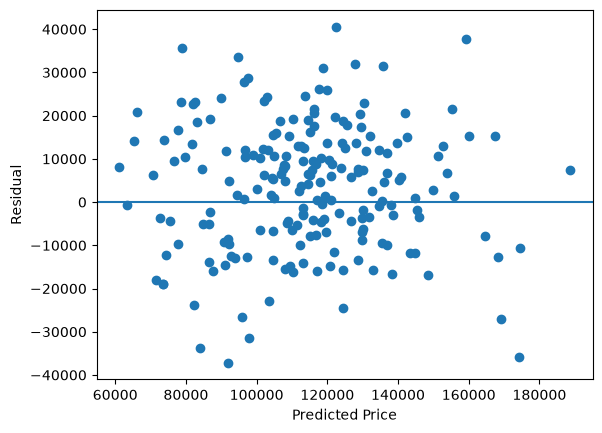

In [ ]:
'''
1 import all required modules
2 import dataset
3 choose features
4 choose target_column
5 import splitter.py
6 split train val and test
7 import baseline.py
8 establish a baseline
9 train linear regression model
10 find mae and rmse
'''

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import(mean_absolute_error, root_mean_squared_error)

data = pd.read_csv("../../Data/house_price_practice.csv")
features = ["size_sqft","bedrooms","age_years","distance_km"]
target_column = "price"

train_data, val_data, test_data = split_dataset(data)

X_train = train_data[features]
y_train = train_data[target_column]
X_val = val_data[features]
y_val = val_data[target_column]

baseline_mae, baseline_rmse = mean_baseline(
    "House Price", train_data, val_data, target_column
)

model = LinearRegression()
model.fit(X_train,y_train)

predictions = model.predict(X_val)

mae = mean_absolute_error(y_val, predictions)
rmse = root_mean_squared_error(y_val, predictions)

print(f"\n\nMAE for Model is {mae:.2f}\nRMSE for Model is {rmse:.2f}\n\n")


if mae<baseline_mae and rmse<baseline_rmse:
    print("Model has cleared the Baseline criteria for both MAE and RMSE.")
else:
    print("The model did'nt cross the Baseline.")

print(model.coef_)
print(model.intercept_)

train_predictions = model.predict(X_train)

train_mae = mean_absolute_error(train_predictions,y_train)
train_rmse = root_mean_squared_error(train_predictions,y_train)

print(f"Training MAE is {train_mae:.2f}")
print(f"Training RMSE is {train_rmse:.2f}")

print(f"Validation MAE is {mae:.2f}")
print(f"Validation RMSE is {rmse:.2f}")

mae_gap = mae - train_mae
rmse_gap = rmse - train_rmse

print("\n\nMAE gap is : ",mae_gap)
print("RMSE gap is : ",rmse_gap)

train_residual = y_train - train_predictions
val_residual = y_val - predictions

plt.scatter(predictions,val_residual)
plt.axhline(0)
plt.xlabel("Predicted Price")
plt.ylabel("Residual")

In [ ]:
'''
1 import all the necessary modules and lib (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, pandas, linear_model - logistic regression.)
2 import the dataset
3 import sklearn.preprocessing for standardscaler which is used to avoid iteration errors
4 create class_bool(if two classes)
5 import split dataset function
6 split the data into train val and test
7 pick feature columns
8 separate x_train and y_train from train data
9 separate x_val and y_val from val data
10 define logistic regression model
11 train the model using X_train and y_train
12 predict on basis of X_val
13 store the prediction in "predictions"
14 compute accuracy precision f1 recall and roc_auc on the basis of y_val and predictions
'''

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_score, f1_score, roc_auc_score, recall_score)
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

data = pd.read_csv("../../Data/student_life.csv")
train_data, val_data, test_data = split_dataset(data)

features = ["Age","Study_Hours","Attendance","Practice_Tests","Sleep_Hours"]

X_train = train_data[features]
y_train = train_data["Passed"]
X_val = val_data[features]
y_val = val_data["Passed"]

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

model = LogisticRegression()
model.fit(X_train_scaled,y_train)

predictions = model.predict(X_val_scaled)

accuracy = accuracy_score(y_val, predictions)
precision = precision_score(y_val, predictions)
recall = recall_score(y_val, predictions)
f1 = f1_score(y_val, predictions)
roc_auc = roc_auc_score(y_val, predictions)

print(f"Accuracy Score is {accuracy}.\nPrecision Score is {precision}.\nRecall Score = {recall}.\nF1 Score is {f1}.\nROC_AUC Score is {roc_auc_score}.")



Accuracy Score is 1.0.
Precision Score is 1.0.
Recall Score = 1.0.
F1 Score is 1.0.
ROC_AUC Score is <function roc_auc_score at 0x000001FE7ABC6CF0>.


In [ ]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score)
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

data = pd.read_csv("../../Data/rice_practice_dataset_1.csv")
data["Class_Bool"] = (data["Class"] == "Cammeo").astype(int)

train_data, val_data, test_data = split_dataset(data)

features = ["Area", "Perimeter", "Major_Axis_Length", "Eccentricity"]

X_train = train_data[features]
y_train = train_data["Class_Bool"]
X_val = val_data[features]
y_val = val_data["Class_Bool"]

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.fit_transform(X_val)
model = LogisticRegression(max_iter = 1000)
model.fit(X_train_scaled,y_train)

predictions = model.predict(X_val_scaled)

accuracy = accuracy_score(y_val, predictions)
precision = precision_score(y_val, predictions)
recall = recall_score(y_val, predictions)
f1 = f1_score(y_val, predictions)

print(f"Accuracy Score is {accuracy}.\nPrecision Score is {precision}.\nRecall Score = {recall}.\nF1 Score is {f1}.")


Accuracy Score is 0.9466666666666667.
Precision Score is 0.9748427672955975.
Recall Score = 0.9281437125748503.
F1 Score is 0.950920245398773


In [ ]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)
import matplotlib.pyplot as plt

def benchmark_model(train_data, val_data, feature_columns, target_column, dataset_name):
    X_train = train_data[feature_columns]
    y_train = train_data[target_column]
    X_val = val_data[feature_columns]
    y_val = val_data[target_column]

    model = LogisticRegression(max_iter=1000)
    model.fit(X_train, y_train)

    predictions = model.predict(X_val)
    probabilities = model.predict_proba(X_val)[:, 1]

    metrics = {
        "accuracy": accuracy_score(y_val, predictions),
        "precision": precision_score(y_val, predictions),
        "recall": recall_score(y_val, predictions),
        "f1": f1_score(y_val, predictions),
        "auc": roc_auc_score(y_val, probabilities),
    }

    print(f"--- {dataset_name} Benchmark ---")
    for name, value in metrics.items():
        print(f"{name}: {value:.4f}")

    with open("benchmark_report.md", "w") as f:
        f.write(f"# Benchmark Report: {dataset_name}\n\n")
        f.write("Model: Logistic Regression\n\n")
        for name, value in metrics.items():
            f.write(f"{name}: {value:.4f}\n")

    cm = confusion_matrix(y_val, predictions)
    plt.figure()
    plt.imshow(cm, cmap="Blues")
    plt.title(f"Confusion Matrix: {dataset_name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.colorbar()
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            plt.text(j, i, cm[i, j], ha="center", va="center")
    plt.savefig("confusion_matrix.png")
    plt.show()

    print("Report + plot saved.")
    return model, metrics


if __name__ == "__main__":
    data = pd.read_csv("rice_practice_dataset.csv")
    data['Class_Bool'] = (data['Class'] == 'Cammeo').astype(int)

    from splitter import split_dataset
    train_data, val_data, test_data = split_dataset(data)

    feature_columns = ['Area', 'Perimeter', 'Major_Axis_Length', 'Eccentricity']

    model, metrics = benchmark_model(
        train_data, val_data,
        feature_columns=feature_columns,
        target_column='Class_Bool',
        dataset_name='Rice (Cammeo vs Osmancik)'
    )

In [ ]:
from sklearn.model_selection import cross_val_score

from sklearn.dummy import DummyClassifier

from sklearn import datasets

from sklearn import svm

from sklearn.model_selection import train_test_split

from sklearn import linear_model



In [ ]:
from sklearn import datasets
from sklearn import svm
from sklearn.model_selection import train_test_split
import numpy as np

X, y = datasets.load_iris(return_X_y=True)
print(X.shape , y.shape)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.4, random_state=0)
print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)

clf = svm.SVC(kernel = 'linear', C =1).fit(X_train,y_train)
clf.score(X_test,y_test)


(150, 4) (150,)
(90, 4) (90,)
(60, 4) (60,)
[1.         1.         1.         1.         0.94444444]
0.9888888888888889


In [8]:
from sklearn import linear_model
reg = linear_model.LinearRegression()
reg.fit([[0, 0],[1, 1],[2 ,2]],[0, 1, 2])

reg.coef_
reg.intercept_

np.float64(1.1102230246251565e-16)

In [ ]:
import pandas as pd

data = pd.read_csv("../../Data/rice_practice_dataset_1.csv")
def split_dataset(data, train_frac = 0.8, val_frac = 0.1, seed = 1):
    shuffled = data.sample(frac=1, random_state = seed).reset_index(drop=True)
    n = len(shuffled)
    train_end = int(n * train_frac)
    val_end = int(train_end + (n * val_frac))
    train = shuffled.iloc[:train_end]
    val = shuffled.iloc[train_end:val_end]
    test = shuffled.iloc[val_end:]

    return train, val, test
train_data, val_data, test_data = split_dataset(data)
print(f"Train: {len(train_data)}, Val: {len(val_data)}, Test: {len(test_data)}")

def majority_baseline(train_data, target_column, dataset_name):
    majority_class_frac = (train_data[target_column].value_counts(normalize=True).max())

    print(f"Baseline accuracy: {majority_class_frac:.2%}")


    with open("baseline_report.md","w") as f:
        f.write("Baseline Report:\n\n")
        f.write(f"Dataset name: {dataset_name}\n")
        f.write("Method: Always predict major class\n")
        f.write(f"Baseline Accuracy: {majority_class_frac:.2%}")
    print("REPORT SAVED")

majority_baseline(train_data, target_column = "Class", dataset_name = "Rice Dataset")


Train: 2400, Val: 300, Test: 300
Baseline accuracy: 50.00%
REPORT SAVED


Basic Statistics do not suggest any outliers.
Defined the following functions:
  * plot_the_dataset
  * plot_a_contiguous_portion_of_dataset


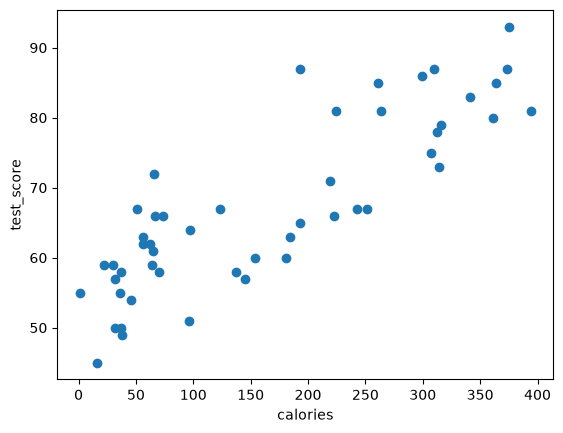

Cannot see an outlier by 50 points plotted
Basic Statistics for each week is similar.
Therefore, weekly differences cannot explain presence of any outlier

 Day 0


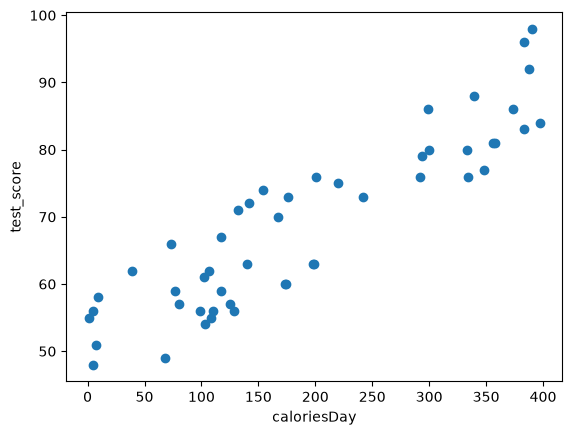


 Day 1


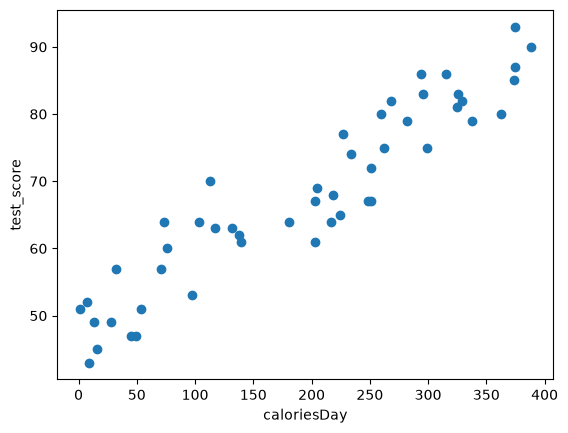


 Day 2


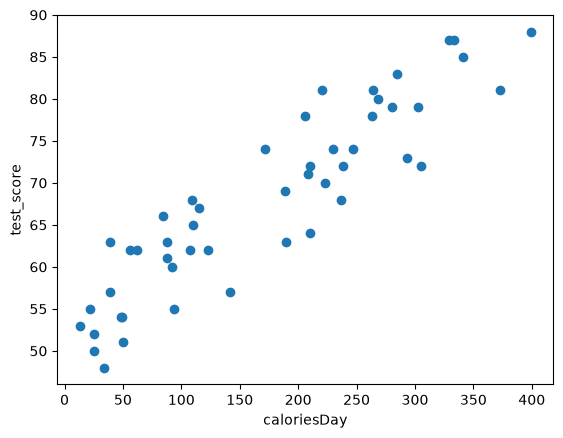


 Day 3


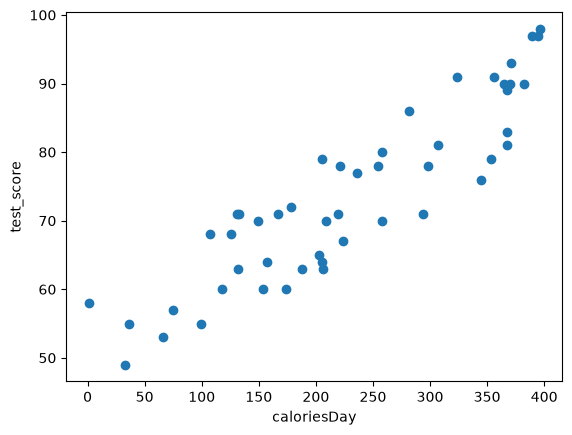


 Day 4


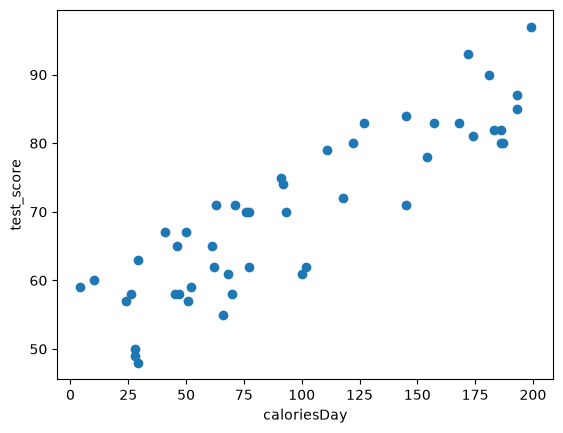


 Day 5


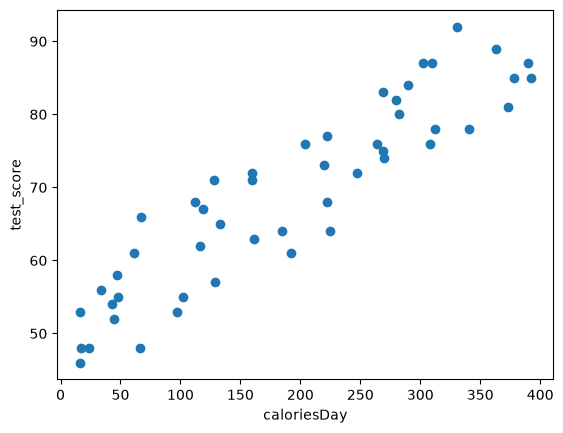


 Day 6


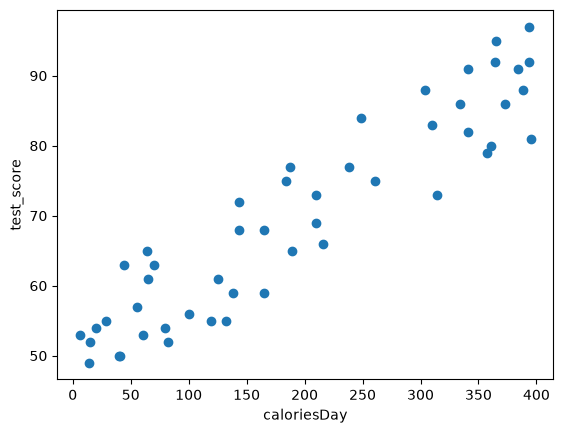

Something wrong with motha foka day 4. That bitch is ranging till 200 while others do 400
The mean of Thursday calories is 93
The mean of calories on days other than Thursday is 201


In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import io

pd.options.display.max_rows = 10
pd.options.display.float_format = "{:.1f}".format

dataset = '''calories,test_score
201,76
142,72
397,84
294,79
334,76
173,60
117,59
174,60
333,80
383,83
77,59
39,62
242,73
7,51
140,63
73,66
102,61
5,48
339,88
388,92
374,86
358,81
292,76
167,70
300,80
348,77
68,49
1,55
198,63
154,74
220,75
9,58
129,56
108,55
356,81
383,96
299,86
107,62
117,67
103,54
110,56
80,57
125,57
132,71
176,73
390,98
199,63
5,56
99,56
39,49
251,67
71,57
7,52
28,49
139,61
227,77
268,82
113,70
32,57
1,51
217,64
248,67
76,60
388,90
9,43
315,86
49,47
97,53
251,72
224,65
299,75
325,81
45,47
203,67
326,83
329,82
282,79
203,61
117,63
218,68
262,75
73,64
205,69
54,51
296,83
132,63
16,45
363,80
138,62
181,64
13,49
294,86
374,85
338,79
375,87
260,80
375,93
234,74
103,64
322,75
210,64
280,79
110,65
329,87
94,55
399,88
264,81
88,61
34,48
373,81
268,80
333,87
208,71
109,68
142,57
39,63
84,66
263,78
247,74
172,74
303,79
92,60
107,62
49,54
293,73
238,72
341,85
48,54
25,52
189,69
230,74
206,78
190,63
237,68
305,72
22,55
223,70
62,62
25,50
115,67
220,81
123,62
210,72
39,57
13,53
88,63
56,62
285,83
50,51
369,94
174,60
206,63
236,77
370,90
66,53
178,72
167,71
133,71
157,64
298,78
1,58
99,55
324,91
389,97
107,68
371,93
36,55
365,90
131,71
132,63
149,70
126,68
254,78
294,71
75,57
224,67
221,78
219,71
307,81
205,64
209,70
382,90
396,98
118,60
367,89
367,83
203,65
33,49
395,97
154,60
205,79
188,63
345,76
258,80
258,70
353,79
282,86
356,91
367,81
91,67
183,82
47,58
118,72
157,83
70,58
172,93
45,58
28,50
92,74
187,80
10,60
76,70
174,81
111,79
91,75
168,83
29,48
181,90
122,80
63,71
193,85
186,82
145,71
77,62
193,87
100,61
71,71
154,78
52,59
46,65
66,55
62,62
51,57
41,67
24,57
186,80
4,59
77,70
29,63
28,49
61,65
26,58
127,83
199,97
68,61
145,84
102,62
50,67
93,70
169,85
119,67
312,78
341,78
67,66
17,48
45,52
24,48
47,58
102,55
280,82
220,73
192,61
269,83
373,81
160,71
290,84
264,76
48,55
269,75
204,76
282,80
112,68
390,87
270,74
247,72
16,46
363,89
133,65
185,64
331,92
16,53
310,87
66,48
128,71
160,72
308,76
225,64
34,56
222,77
392,85
97,53
222,68
302,87
378,85
61,61
161,63
129,57
43,54
116,62
173,71
189,65
361,80
187,77
314,73
341,91
165,59
44,63
184,75
341,82
119,55
70,63
165,68
394,92
80,54
65,61
29,55
64,65
310,83
384,91
304,88
216,66
6,53
55,57
249,84
395,81
41,50
334,86
394,97
100,56
125,61
14,49
61,53
143,72
373,86
238,77
138,59
388,88
357,79
20,54
82,52
261,75
210,73
15,52
210,69
364,92
365,95
132,55
143,68
40,50
88,64
35,55
18,44
56,47
109,55
268,78
178,67
399,82
11,45
235,74
215,73
200,69
220,78
249,82
250,79
121,68
210,71
165,70
265,79
290,87
384,88
207,69
16,54
193,62
307,75
292,76
312,78
345,83
67,56
180,75
126,69
299,86
143,60
251,66
371,86
25,59
27,56
159,59
125,69
114,56
66,50
240,82
184,68
196,74
21,44
254,73
364,86
127,59
347,93
157,71
161,65
315,83
57,50
276,79
69,49
300,79
83,56
199,75
367,95
247,83
15,49
136,72
341,87
129,67
284,82
248,70
68,55
320,81
280,80
36,62
272,85
171,76
161,74
307,77
365,84
159,58
299,86
45,58
244,73
215,68
60,50
259,75
269,76
382,88
61,48
185,74
40,61
373,87
326,86
373,93
77,55
358,94
70,48
303,87
220,68
85,64
224,81
94,55
167,63
329,86
137,60
246,76
112,62
22,47
99,53
58,55
170,61
196,73
105,58
241,80
259,84
248,71
357,92
262,75
105,60
37,58
347,88
106,54
102,57
184,70
166,68
63,64
301,85
306,72
44,52
331,90
159,67
72,53
208,77
284,83
168,74
198,66
291,84
218,80
74,49
279,82
244,83
263,74
287,79
194,77
359,84
364,85
391,82
278,78
13,51
111,60
169,72
339,78
213,69
95,65
159,58
214,64
3,47
234,77
332,75
308,87
196,73
95,59
350,77
29,60
220,69
187,77
50,52
91,64
326,82
236,70
247,70
174,70
213,63
184,68
79,53
121,67
363,89
149,72
275,77
320,77
319,80
128,54
319,83
361,88
49,57
374,92
333,83
188,68
242,82
376,93
107,58
282,72
0,42
26,58
209,79
58,55
182,68
227,68
48,54
347,82
28,60
79,49
155,69
193,78
282,77
180,95
176,87
51,69
137,76
158,78
102,62
170,92
101,69
44,63
199,84
39,50
43,59
15,57
55,64
162,91
39,61
12,45
84,64
13,48
171,93
127,73
1,50
66,65
2,53
92,60
193,91
36,51
31,54
199,90
5,56
103,65
124,76
80,58
0,49
51,67
108,81
66,66
96,72
54,61
85,71
122,72
99,75
135,82
30,59
58,56
116,81
78,60
119,79
47,63
74,66
224,64
237,81
267,71
262,68
314,76
354,84
232,71
72,55
98,57
55,56
244,78
222,65
364,80
4,46
342,82
341,85
200,71
208,65
339,80
128,65
189,64
10,45
278,74
208,79
257,79
232,69
148,58
146,61
158,64
215,69
344,84
352,85
65,55
254,67
273,85
256,71
107,66
169,75
34,61
360,90
282,78
36,46
289,80
186,62
18,45
190,60
244,74
191,74
389,82
355,90
70,57
10,52
120,61
204,70
199,70
131,58
399,88
111,67
36,60
22,46
385,91
59,57
41,56
181,60
338,81
335,77
390,97
271,75
167,63
349,76
325,77
90,67
292,81
298,86
185,74
25,51
218,69
42,57
377,91
332,90
1,53
9,43
298,85
186,63
40,51
74,49
259,76
375,87
51,60
165,70
280,78
92,55
316,79
358,92
43,58
294,74
199,76
121,57
311,88
205,79
87,64
3,59
128,55
183,69
339,91
101,63
181,68
361,83
371,94
76,49
252,67
102,55
1,53
234,80
217,64
351,92
360,95
336,81
19,50
353,76
154,59
263,84
249,76
118,65
187,70
277,72
293,71
220,76
289,72
250,71
136,66
96,55
284,73
270,82
238,75
347,77
322,83
13,50
79,57
33,58
11,58
34,58
376,90
242,79
351,82
57,51
22,50
226,77
228,68
253,71
363,86
144,68
55,55
98,59
373,86
85,51
128,61
332,81
59,57
55,47
351,81
96,51
309,88
323,80
105,59
290,73
377,82
352,80
276,71
251,77
224,81
277,86
141,66
143,64
111,63
253,71
354,94
122,67
358,79
86,52
222,80
130,65
53,52
318,88
219,72
221,67
191,66
82,64
35,57
176,65
110,53
252,71
21,60
12,43
63,52
85,64
118,64
215,70
27,52
142,66
387,80
334,82
147,56
154,67
285,84
371,80
358,89
144,56
283,76
44,61
298,79
318,74
74,54
229,68
308,89
391,95
377,93
117,60
385,92
391,94
244,66
350,87
272,72
268,77
293,86
188,68
171,63
250,79
239,68
389,88
92,67
129,57
348,89
278,84
160,69
245,66
275,77
249,74
332,81
388,90
158,65
60,62
325,87
216,72
31,55
397,86
271,76
192,70
59,50
195,72
383,81
267,81
279,76
135,64
362,85
37,50
384,84
49,60
49,60
115,56
199,68
203,65
326,75
333,92
153,62
248,72
212,69
38,49
361,87
302,86
381,94
43,62
79,55
274,74
44,47
252,79
188,62
357,84
94,65
143,66
60,49
26,56
193,65
363,84
322,87
120,67
248,73
312,89
298,81
142,73
261,85
272,72
49,58
249,74
204,79
34,58
69,53
180,71
210,70
59,53
47,58
39,66
192,97
177,91
109,69
177,82
67,66
107,71
70,58
185,93
49,53
126,74
96,64
37,48
152,79
67,72
177,86
13,61
123,67
154,75
81,69
93,73
66,72
61,67
53,58
152,81
112,72
8,43
159,77
9,53
133,76
110,75
25,59
144,83
155,81
1,45
50,60
6,55
116,70
117,82
135,74
93,64
190,90
55,65
189,85
60,64
183,95
75,57
135,70
156,80
276,83
298,72
146,70
339,76
46,53
0,55
355,87
53,61
75,56
233,67
336,92
342,89
378,85
319,84
216,75
72,52
232,81
156,74
281,75
398,95
312,90
285,83
228,79
288,85
145,61
0,45
159,74
383,85
121,69
28,59
263,72
72,52
70,60
73,64
9,47
320,87
155,66
273,70
187,67
372,93
324,74
13,46
1,43
263,73
28,57
102,64
390,88
386,82
45,50
10,44
216,79
17,59
221,78
398,81
95,51
340,78
29,62
145,57
80,49
196,65
299,86
42,60
158,58
392,89
130,56
299,88
18,59
4,52
337,77
290,73
58,59
136,59
270,83
161,75
376,97
100,65
341,83
250,70
213,73
344,93
287,83
18,58
290,71
229,76
66,53
344,81
392,84
254,80
4,44
298,72
58,49
342,77
227,72
184,63
33,52
112,69
101,57
310,74
152,64
303,83
301,82
385,95
370,91
285,70
341,85
41,47
311,89
127,62
174,74
264,79
125,70
213,74
148,63
303,87
392,91
205,77
139,65
273,73
116,62
169,60
71,58
141,72
236,77
163,58
221,66
303,89
89,57
258,77
326,83
181,73
97,68
255,77
218,71
345,93
16,48
77,53
368,88
69,57
129,66
257,82
346,83
383,81
320,84
315,86
89,54
252,75
124,60
65,65
365,78
363,94
168,60
112,60
259,75
384,97
100,64
382,81
87,66
124,54
249,68
341,92
134,65
210,76
386,92
287,87
328,85
376,85
333,78
319,82
313,88
223,66
230,75
103,66
256,79
368,84
309,88
129,58
187,75
388,89
257,79
210,70
168,66
325,78
318,84
336,87
233,73
374,81
93,56
23,59
390,82
97,64
385,92
386,89
209,63
30,49
335,85
295,77
70,58
247,67
107,62
347,91
72,63
46,53
41,48
114,54
145,67
373,86
124,53
387,97
18,46
85,67
344,93
142,56
243,67
87,65
258,70
290,87
399,96
137,58
48,59
157,67
148,64
9,56
175,60
290,81
100,52
233,66
41,46
100,64
49,56
235,80
308,79
322,89
148,60
33,55
397,91
75,57
6,47
102,59
166,75
60,59
54,62
352,80
353,79
380,81
283,81
395,91
69,64
184,69
64,59
98,56
92,60
291,75
343,93
322,78
29,45
17,46
362,78
179,73
64,56
4,59
59,49
267,73
4,44
388,85
311,78
257,69
346,82
188,73
185,66
41,55
179,63
340,81
112,58
99,61
364,82
253,67
145,61
195,69
214,73
346,81
356,86
215,78
394,81
277,77
199,75
35,62
62,64
161,65
138,68
37,49
6,55
169,67
10,58
30,56
190,61
36,53
221,74
134,66
297,73
36,49
8,48
58,56
45,63
148,83
90,74
187,89
111,70
33,60
75,62
71,73
79,65
87,59
36,64
139,85
3,58
32,50
58,63
72,65
50,53
39,63
7,47
97,71
120,77
78,58
22,59
9,52
60,64
132,76
93,68
102,72
72,68
151,83
46,54
56,63
85,69
100,69
186,96
11,55
150,81
144,85
82,71
93,72
71,57
59,70
118,79
126,67
117,73
164,90
142,73
102,64
359,77
240,80
42,59
186,75
170,61
327,89
382,86
216,70
249,81
139,61
258,68
153,62
230,70
104,59
207,76
212,72
354,81
139,57
43,60
24,53
0,57
146,57
150,56
192,78
383,96
127,67
52,61
20,56
47,51
39,58
75,62
106,53
31,55
112,57
214,68
330,84
130,59
282,82
167,63
279,76
136,57
35,53
373,81
69,51
179,66
361,89
88,55
327,79
398,83
237,76
175,68
112,68
372,96
229,70
112,57
331,85
157,73
36,52
64,54
237,78
343,86
141,56
394,85
151,58
193,62
289,70
285,70
359,90
395,89
38,52
339,75
41,51
378,82
313,76
269,77
372,88
34,51
243,67
310,74
62,52
113,70
113,70
394,84
297,72
303,88
182,70
34,54
24,46
343,90
141,67
129,59
67,57
312,88
276,79
35,62
324,80
375,82
189,76
195,66
44,50
'''


training_df = pd.read_csv(io.StringIO(dataset), on_bad_lines = 'warn')
# print(training_df.describe())
print("Basic Statistics do not suggest any outliers.")

def plot_the_dataset(feature, label, number_of_points_to_plot):

    plt.xlabel(feature)
    plt.ylabel(label)

    random_examples = training_df.sample(n=number_of_points_to_plot)
    plt.scatter(random_examples[feature],random_examples[label])
    plt.show()

def plot_a_contiguous_portion_of_dataset(feature, label, start, end):
    plt.xlabel(feature+ "Day")
    plt.ylabel(label)

    plt.scatter(training_df[feature][start:end],training_df[label][start:end])
    plt.show()

print("Defined the following functions:")
print("  * plot_the_dataset")
print("  * plot_a_contiguous_portion_of_dataset")


plot_the_dataset("calories","test_score",number_of_points_to_plot = 50)
print("Cannot see an outlier by 50 points plotted")


# print(training_df[0:350].describe())
# print(training_df[350:700].describe())
# print(training_df[700:1050].describe())
# print(training_df[1050:1400].describe())

print("""Basic Statistics for each week is similar.
Therefore, weekly differences cannot explain presence of any outlier""")

for i in range(0,7):
    start = i * 50
    end = start + 49
    print("\n Day %d" % i)
    plot_a_contiguous_portion_of_dataset("calories","test_score",start,end)

print("Something wrong with motha foka day 4. That bitch is ranging till 200 while others do 400")

# @title Task 5: Solution (expand this code block to view) { display-mode: "form" }

# You could use a variety of metrics to fully compare Thursday to the other
# six days, but this answer simply focuses on the mean.

running_total_of_thursday_calories = 0
running_total_of_non_thursday_calories = 0
count = 0
for week in range(0,4):
  for day in range(0,7):
    for subject in range(0,50):
      position = (week * 350) + (day * 50) + subject
      if (day == 4):  # Thursday
        running_total_of_thursday_calories += training_df['calories'][position]
      else:  # Any day except Thursday
        count += 1
        running_total_of_non_thursday_calories += training_df['calories'][position]

mean_of_thursday_calories = running_total_of_thursday_calories / 200
mean_of_non_thursday_calories = running_total_of_non_thursday_calories / 1200

print("The mean of Thursday calories is %.0f" % (mean_of_thursday_calories))
print("The mean of calories on days other than Thursday is %.0f" % (mean_of_non_thursday_calories))

In [5]:
import pandas as pd
pd.options.display.max_rows = 10
pd.options.display.float_format = "{:.1f}".format

training_df = pd.read_csv("../../data/california_housing_train.csv")
training_df.head()
training_df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,17000.0,17000.0,17000.0,17000.0,17000.0,17000.0,17000.0,17000.0,17000.0
mean,-119.6,35.6,28.6,2643.7,539.4,1429.6,501.2,3.9,207300.9
std,2.0,2.1,12.6,2179.9,421.5,1147.9,384.5,1.9,115983.8
min,-124.3,32.5,1.0,2.0,1.0,3.0,1.0,0.5,14999.0
25%,-121.8,33.9,18.0,1462.0,297.0,790.0,282.0,2.6,119400.0
50%,-118.5,34.2,29.0,2127.0,434.0,1167.0,409.0,3.5,180400.0
75%,-118.0,37.7,37.0,3151.2,648.2,1721.0,605.2,4.8,265000.0
max,-114.3,42.0,52.0,37937.0,6445.0,35682.0,6082.0,15.0,500001.0
